<a href="https://colab.research.google.com/github/T1toh/30Days_of_SQL/blob/main/MODULE_5_%7C_LESSON_1_Non_linearity_Foundations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **CAPSTONE REVIEW**
## MODULE 5 | LESSON 1: Non-linearity Foundations

| | |
|:---|:---|
|**Reading Time** | 3.5h |
|**Prior Knowledge** | Linear regression, time series analysis, basic derivatives theory, statistical testing, optimization methods |
|**Keywords** | Non-linearity, BDS test, convexity, gamma exposure, threshold models, GAMs, mutual information, non-linear transformations, heteroskedasticity, regime switching |

---

## **Introduction**

Non-linearity in financial markets is like gravity—invisible yet everywhere, shaping every price movement and risk calculation we encounter.

A bit more precisely, non-linearity means that doubling your input doesn't double your output, that small changes can have large effects (or vice versa), and that the whole often behaves quite differently from the sum of its parts. Think of it this way: if markets were purely linear, a 2% market drop would simply be twice as bad as a 1% drop. Yet anyone who lived through 2008 knows this isn't remotely true—the damage accelerates, correlations spike, and what seemed like independent risks suddenly move in lockstep.

It pays to understand why non-linearity matters so profoundly. Portfolio managers discover that their carefully calibrated mean-variance optimizations work beautifully until correlations shift (why do they always seem to shift at the worst possible moment?). Option traders live and breathe non-linearity—their entire edge comes from understanding how a stock move of $X$ translates into option profits of $X^2$, or $X^3$, or sometimes nothing at all. Even the humble bond trader faces convexity, that peculiar feature where falling yields boost prices more than rising yields hurt them.

Note that recognizing non-linearity is one thing; modeling it effectively is quite another.

This lesson establishes the mathematical and practical foundations for wrestling with non-linear relationships. We begin with the sources—where does non-linearity come from, and why should you care? The BDS test then provides our statistical flashlight, illuminating non-linear dependencies that correlation measures completely miss. We dive deep into option convexity (arguably the most financially significant non-linearity you'll encounter), explore threshold models that capture regime changes, and master modern computational tools from GAMs to mutual information.

Surprisingly, the goal isn't always to eliminate non-linearity—sometimes it's your best friend.

## **1. Sources of Non-linearity in Financial Data**

### **1.1 Structural Non-linearities**

For the purposes of financial modeling, structural non-linearities are relationships that are non-linear by construction—they couldn't be linear even if they wanted to be.

Consider bonds. The price-yield relationship follows this deceptively simple formula:

$$P = \sum_{t=1}^{T} \frac{CF_t}{(1+y)^t}$$

Look carefully at that denominator. Each cash flow gets divided by $(1+y)$ raised to increasingly higher powers—this guarantees non-linearity. A 1% yield decrease doesn't just flip the sign on a 1% yield increase; it produces a larger price gain than the corresponding loss. This asymmetry (captured by the convexity measure) means duration tells only half the story.

Options take non-linearity to extremes. The payoff function at expiration—that famous hockey stick shape—represents perhaps the starkest non-linearity in finance:

$$\text{Payoff} = \max(S_T - K, 0)$$

Below the strike, the option might as well not exist (why would you exercise it?). Above the strike, every dollar matters. During the option's life, Black-Scholes smooths this kink into a graceful curve, but the non-linearity persists through delta and especially gamma. A stock at $99 versus $101 might seem like a small difference—unless your strike is $100.

### **1.2 Market Microstructure Non-linearities**

Here's an uncomfortable truth: your trades move the market, and not in a linear fashion.

Small orders slip through almost unnoticed. Medium orders start to bite. Large orders? They can move markets dramatically. Empirical studies typically find:

$$\text{Impact} = \alpha \cdot \text{Volume}^\beta$$

with $\beta$ hovering between 0.5 and 0.8. This means doubling your order size increases impact by only 40-70%—until you hit capacity constraints and impact accelerates dramatically. Algorithmic traders who assume zero or linear impact often discover this non-linearity the hard way (through unexpectedly poor execution).

### **1.3 Volatility Dynamics**

Volatility refuses to play by linear rules. Consider the leverage effect—one of finance's most robust empirical regularities.

When markets fall 5%, implied volatilities might jump 3 points. When markets rise 5%, volatilities might drop only 1 point. This asymmetry gets captured in models like GJR-GARCH:

$$
\sigma_t^2 = \omega + \alpha \epsilon_{t-1}^2 + \gamma \epsilon_{t-1}^2 I_{(\epsilon_{t-1}<0)} + \beta \sigma_{t-1}^2
$$

That indicator function $I_{(\epsilon_{t-1}<0)}$ is doing heavy lifting—it literally switches on extra volatility for negative returns. The parameter $\gamma$ measures how much worse bad news is than good news (empirically, about twice as impactful).

More subtly, volatility clusters. High volatility begets high volatility—October 1987 wasn't just one bad day but weeks of extreme moves. This temporal non-linearity breaks the comfortable assumption that tomorrow's risk looks like today's.

### **1.4 Regime-Dependent Behavior**

Markets have moods. What works in a bull market fails spectacularly in a bear market (remember "buy the dip" in 2022?).

During calm periods, correlations behave themselves—stocks maintain their individual characteristics, sectors show modest correlations, international diversification actually diversifies. During crises? Correlations spike toward one, turning your carefully diversified portfolio into one giant bet. This regime-switching behavior represents a profound non-linearity: the rules of the game literally change.

### **1.5 Behavioral Non-linearities**

Humans aren't wired for linearity. Prospect theory demonstrates this beautifully through its value function:

$$v(x) = \begin{cases} x^\alpha & \text{if } x \geq 0 \\ -\lambda(-x)^\beta & \text{if } x < 0 \end{cases}$$

Those exponents ($\alpha \approx \beta \approx 0.88$) create diminishing sensitivity—the difference between winning $1,000 and $2,000 feels larger than between $101,000 and $102,000. The loss aversion parameter ($\lambda \approx 2.25$) captures another non-linearity: losses hurt roughly twice as much as equivalent gains feel good.

## **2. Testing for Non-linear Dependencies: The BDS Test**

### **2.1 Motivation and Intuition**

Linear correlation is like a flashlight that only illuminates straight paths—useful, but it misses all the interesting curves and corners.

Consider this troubling possibility: two variables could have exactly zero correlation yet be perfectly dependent. How? Imagine $Y = X^2$ where $X \sim N(0,1)$. The correlation is zero (positive and negative $X$ values cancel), yet knowing $X$ tells you $Y$ exactly. Traditional tests like Ljung-Box would declare independence—wrongly.

Enter the BDS test, your non-linear dependency detector.

### **2.2 The Correlation Integral**

The test's genius lies in examining patterns in phase space. We embed our time series into higher dimensions by creating vectors:

$$X_t^m = (x_t, x_{t+1}, ..., x_{t+m-1})$$

Why does this help? Because non-linear dependencies often reveal themselves through clustering in higher dimensions. The correlation integral measures this clustering:

$$C_m(\epsilon) = \frac{2}{T_m(T_m-1)} \sum_{t=1}^{T_m-1} \sum_{s=t+1}^{T_m} I(||X_t^m - X_s^m|| < \epsilon)$$

Think of it as asking: "What fraction of point pairs lie within distance $\epsilon$ of each other?"

### **2.3 The BDS Statistic**

Here's the key insight: if data is truly i.i.d., then the probability of two $m$-dimensional points being close equals the probability of their one-dimensional components being close, raised to the $m$th power:

$$C_m(\epsilon) = [C_1(\epsilon)]^m$$

Violations of this relationship signal dependence. The BDS statistic formalizes this:

$$BDS_{m,\epsilon} = \sqrt{T_m} \frac{C_m(\epsilon) - [C_1(\epsilon)]^m}{\sigma_{m,\epsilon}}$$

Under the null of independence, this follows a standard normal distribution.

### **2.4 Implementation Considerations**

It pays to be careful about implementation details (why?). You need to choose:

**Embedding dimension ($m$)**: Test multiple values (2, 3, 4, 5) since different dependencies appear at different scales. Too low and you miss complex patterns; too high and you lose statistical power.

**Distance parameter ($\epsilon$)**: Convention suggests 0.5, 1.0, 1.5, and 2.0 times the standard deviation. Think of these as different magnifications—some patterns only appear at certain scales.

**Pre-filtering**: Apply to residuals from GARCH models to isolate truly non-linear dependencies from mere volatility clustering.

### **2.5 Interpretation and Power**

The BDS test detects many forms of misbehavior: chaos, non-linear dynamics, structural breaks, omitted non-linear terms. This power is also its limitation—rejection tells you something non-linear lurks but not what.

In [ ]:
!pip install arch

# Imports
import yfinance as yf
import numpy as np
import pandas as pd

from statsmodels.tsa.stattools import bds
from arch import arch_model

# Downloading data
#spx = yf.download("^GSPC", start="2000-01-01")["Close"]
spx = pd.read_csv("/spx.csv", index_col="Date")
logret = np.log(spx).diff().dropna()
logret.name = "r"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 21.5 MB/s eta 0:00:00


We follow Brock-Dechert-Scheinkman practice:
- embedding dimensions m = 2, 3, 4
- neighbourhood sizes $\epsilon = \{0.5, 1.0, 1.5\} x \sigma $ where $\sigma$ is the std of returns

The BDS statistic is asymptotically $N(0,1), |z|>1.96 \Rightarrow \text{reject at } 5\%$.

In [ ]:

sigma = logret.std().values
m_vals  = [2, 3, 4]
eps_mul = [0.5, 1.0, 1.5]

# BDS on raw returns

rows  = []

for m in m_vals:
    for k in eps_mul:
        stats, pvals = bds(logret.to_numpy(), max_dim=m, epsilon=k * sigma)

        # robust to both scalar and array outputs
        z = float(np.atleast_1d(stats)[-1])
        p = float(np.atleast_1d(pvals)[-1])

        rows.append({"m": m, "ε": f"{k:.1f}σ", "z": z, "p": p})

bds_raw = pd.DataFrame(rows)
bds_raw


,m,ε,z,p
0,2,0.5σ,16.955514,1.752214e-64
1,2,1.0σ,17.555842,5.366483e-69
2,2,1.5σ,18.862816,2.306058e-79
3,3,0.5σ,26.805170,2.812557e-158
4,3,1.0σ,26.135535,1.439263e-150
5,3,1.5σ,26.270958,4.119028e-152
6,4,0.5σ,36.375648,1.033288e-289
7,4,1.0σ,32.694865,1.847539e-234
8,4,1.5σ,30.881759,2.099644e-209


Typical outcome: several cells show $|z| \gg1.96$, so we reject i.i.d.;
unspecific non‑linearity may be lurking, but volatility clustering is the prime suspect.

In [ ]:
# Extract residuals
garch = arch_model(logret * 100, p=1, q=1, mean="Zero")
fit = garch.fit(disp="off")
std_resid = fit.std_resid / 100   # scale back to raw returns


In [ ]:
# Code Cell 6
rows = []
for m in m_vals:
    for k in eps_mul:
        stats, pvals = bds(std_resid.to_numpy(), max_dim=m, epsilon=k * sigma)
        z = float(np.atleast_1d(stats)[-1])
        p = float(np.atleast_1d(pvals)[-1])
        rows.append({"m": m, "ε": f"{k:.1f}σ", "z": z, "p": p})

bds_filt = pd.DataFrame(rows)
bds_filt


,m,ε,z,p
0,2,0.5σ,-2.077437,0.037761
1,2,1.0σ,-2.629022,0.008563
2,2,1.5σ,-2.533574,0.011291
3,3,0.5σ,0.581808,0.560696
4,3,1.0σ,-0.491494,0.623077
5,3,1.5σ,-0.858231,0.390765
6,4,0.5σ,2.266020,0.023450
7,4,1.0σ,0.780248,0.435245
8,4,1.5σ,-0.049575,0.960461


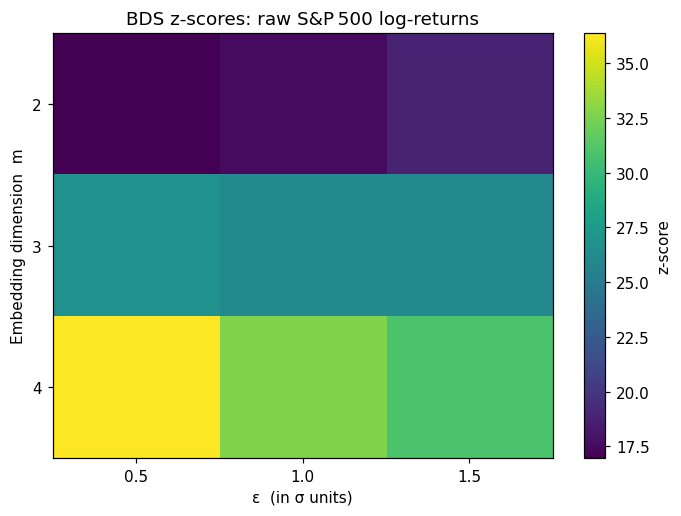

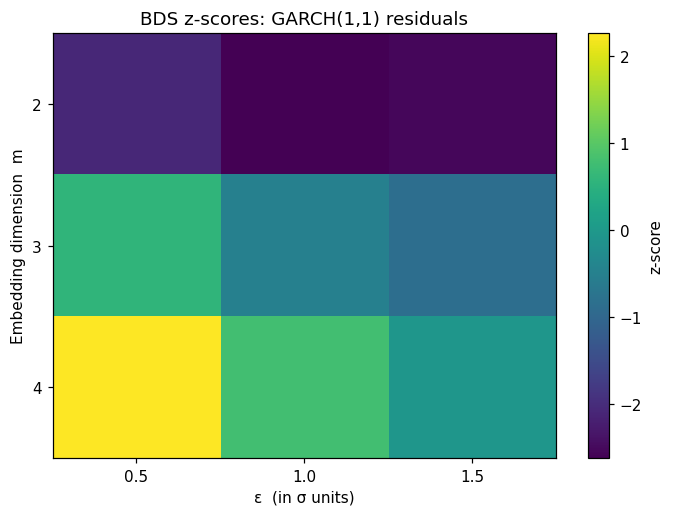

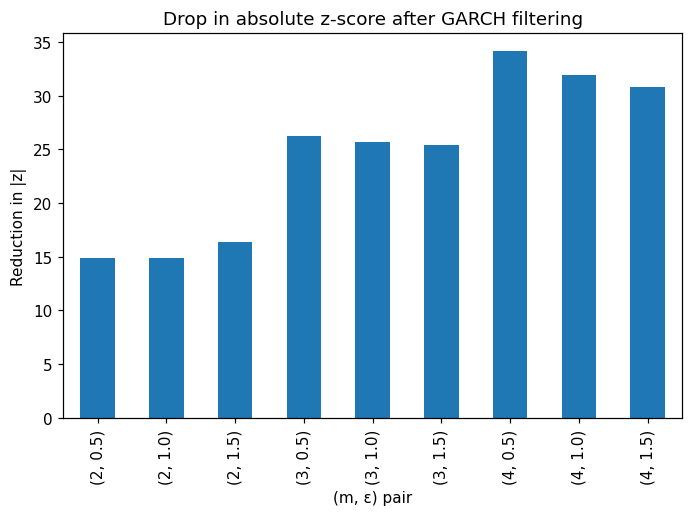

In [ ]:
import matplotlib.pyplot as plt


# Re‑use the two DataFrames that already exist in the notebook
# (bds_raw and bds_filt) and make tidy pivot tables for plotting.

def make_pivot(df: pd.DataFrame, value: str) -> pd.DataFrame:
    """Return a m × epsilon table ready for imshow."""
    tbl = df.copy()
    # strip the trailing 'σ' and cast to float so eps is numeric & sortable
    tbl["eps_float"] = tbl["ε"].str.rstrip("σ").astype(float)
    tbl = tbl.pivot(index="m", columns="eps_float", values=value)
    # ensure natural order (increasing m downward, ε across)
    tbl.sort_index(axis=0, inplace=True)
    tbl.sort_index(axis=1, inplace=True)
    return tbl

raw_piv  = make_pivot(bds_raw,  "z")
filt_piv = make_pivot(bds_filt, "z")

# 1) Heat‑map of z‑scores for raw returns
plt.figure(dpi=110)
plt.title("BDS z‑scores: raw S&P 500 log‑returns")
plt.imshow(raw_piv, aspect="auto")
plt.xticks(np.arange(len(raw_piv.columns)), raw_piv.columns)
plt.yticks(np.arange(len(raw_piv.index)),   raw_piv.index)
plt.xlabel("ε  (in σ units)")
plt.ylabel("Embedding dimension  m")
plt.colorbar(label="z‑score")
plt.tight_layout()
plt.show()

# 2) Heat‑map of z‑scores for GARCH‑filtered residuals
plt.figure(dpi=110)
plt.title("BDS z‑scores: GARCH(1,1) residuals")
plt.imshow(filt_piv, aspect="auto")
plt.xticks(np.arange(len(filt_piv.columns)), filt_piv.columns)
plt.yticks(np.arange(len(filt_piv.index)),   filt_piv.index)
plt.xlabel("ε  (in σ units)")
plt.ylabel("Embedding dimension  m")
plt.colorbar(label="z‑score")
plt.tight_layout()
plt.show()

# 3) Absolute‑z reduction bar plot
# Flatten the two matrices into aligned Series
raw_flat  = raw_piv.stack()
filt_flat = filt_piv.stack()
reduction = (np.abs(raw_flat) - np.abs(filt_flat)).rename("Δ|z| (raw – filt)")

plt.figure(dpi=110)
reduction.plot(kind="bar")
plt.title("Drop in absolute z‑score after GARCH filtering")
plt.xlabel("(m, ε) pair")
plt.ylabel("Reduction in |z|")
plt.tight_layout()
plt.show()

**BDS Diagnostics after Volatility Adjustment**

| symbol | meaning |
|:------:|---------|
| **m** | embedding dimension ($m=2$ pairs, $m=3$ triplets, $m=4$ quadruplets) |
| **ε** | neighbourhood radius in units of the return s.d. $\sigma$ |
| **z** | BDS statistic ($\sim\mathcal N(0,1)$ under i.i.d.) |
| **p** | two‑sided $p$‑value |


**Raw log‑returns (`^GSPC`, 2000 – today)**

* Every $(m,\varepsilon)$ cell sits far beyond the $\pm\,1.96$ band  
  ($|z|\approx17\!-\!37,\;p\le10^{-64}$).  
* **Interpretation.** The i.i.d. null is emphatically rejected, consistent with
  classic **volatility clustering** in equity data.



**GARCH(1,1)‑standardised residuals**

* $6$ of $9$ cells now fall inside $\pm1.96$ ($p=0.04\!-\!0.96$).  
* Three cells—$(m=2,\varepsilon\le1.5\sigma)$ and $(m=4,\varepsilon=0.5\sigma)$—
  remain borderline significant ($|z|\approx2.1\!-\!2.7,\;p\approx0.01\!-\!0.04$).


**Residual significance – probable causes**

1. **Model parsimony** (leverage, fat tails not captured by plain GARCH).  
2. **Microstructure noise** (bid–ask bounce dominates tiny $\varepsilon$).  
3. **Regime shifts** (crisis vs. calm requires threshold or Markov‑switching volatility).



**Reading the visuals**

1. **Heat‑map #1 (raw)** – a solid yellow‑green block: every cell crushes the
   $\pm1.96$ threshold.  
2. **Heat‑map #2 (residuals)** – palette cools to green/blue near $0$; only one
   narrow yellow stripe (high $m$, small $\varepsilon$) hints at remaining dependence.  
3. **Bar chart ($\Delta|z|$)** – positive bars everywhere; the statistic drops
   by $15\!-\!35$ s.e. after filtering, largest for $m=4$ cells → **multi‑step
   dependence was almost entirely volatility‑driven.**

**Key takeaway:** Diagnose non‑linearity on *standardised residuals*; otherwise heteroskedasticity masquerades as deeper structure.  



## **3. Option Convexity and Gamma Exposure**

### **3.1 From Linear to Non-linear Sensitivities**


A stock position is boringly linear: buy 100 shares, and every $1 move means $100 gained or lost. Options? Their delta changes continuously, creating a moving target. This rate of change—gamma—quantifies the non-linearity:

$$\Gamma = \frac{\partial^2 V}{\partial S^2} = \frac{\partial \Delta}{\partial S}$$

For a Black-Scholes call:

$$\Gamma = \frac{\phi(d_1)}{S\sigma\sqrt{T}}$$

Notice what drives gamma: the normal density $\phi(d_1)$ peaks at-the-money, time decay $\sqrt{T}$ in the denominator explodes near expiration, and volatility $\sigma$ moderates the effect. Maximum gamma occurs precisely where traders feel most uncertainty—ATM options near expiration.

### **3.2 The Gamma Trading Paradigm**

Gamma transforms trading from a directional game to a volatility game. Your P&L becomes:

$$\text{P\&L} \approx \Delta \cdot \Delta S + \frac{1}{2}\Gamma \cdot (\Delta S)^2 - \theta \cdot \Delta t$$

Look at that squared term—it's always positive for long gamma positions (why would a square be negative?). This creates a beautiful trade: you profit from movement regardless of direction. The catch? Theta decay, time's tax on optionality.

Short gamma positions face the opposite dynamic. That squared term works against you—small moves are manageable, but large moves create accelerating losses. It's like writing insurance: collecting premiums works great until the hurricane hits.

### **3.3 Dynamic Hedging and Non-linearity**

Delta-neutral doesn't mean set-and-forget. As the underlying moves, your hedge requirements change by:

$$\Delta_{\text{hedge}} = -\Gamma \cdot \Delta S$$

This creates the classic rebalancing pattern. Long gamma positions naturally buy low and sell high—the market moves down, delta decreases, you buy stock; market rallies, delta increases, you sell. Short gamma positions require buying high and selling low, a structural disadvantage offset only by collecting theta.

The rebalancing frequency matters enormously. Too frequent and transaction costs eat your edge; too infrequent and gap risk destroys your "hedge."

### **3.4 Convexity in Multi-Asset Contexts**

Single-asset gamma is just the beginning. Multi-asset portfolios face cross-gammas:

$$\Gamma_{ij} = \frac{\partial^2 V}{\partial S_i \partial S_j}$$

These cross-effects can dominate portfolio risk. A correlation option might have modest gammas to each underlying but massive cross-gamma. Basket options, quanto products, and even vanilla options on correlated underlyings all exhibit these effects.

Suddenly, your nice diagonal gamma matrix becomes fully populated—risk exists not just in individual moves but in their combinations.

### **3.5 Vega Convexity and Higher-Order Effects**

Price isn't the only dimension with convexity. Volatility sensitivity itself changes non-linearly:

$$\text{Vomma} = \frac{\partial^2 V}{\partial \sigma^2} = \frac{\partial \text{Vega}}{\partial \sigma}$$

$$\text{Vanna} = \frac{\partial^2 V}{\partial S \partial \sigma} = \frac{\partial \text{Delta}}{\partial \sigma} = \frac{\partial \text{Vega}}{\partial S}$$

These Greeks matter when correlations break down. During volatility spikes, your carefully vega-hedged book can still hemorrhage money through vomma. Vanna explains why out-of-the-money puts gain delta faster than models predict when volatility rises—a critical effect for tail hedging.

## **4. Threshold Models: Bridging Linear and Non-linear Worlds**

### **4.1 The Threshold Autoregressive (TAR) Model**

Some relationships change personality at critical points.

TAR models capture this behavior by allowing different dynamics in different regimes:

$$y_t = \begin{cases}
\phi_0^{(1)} + \sum_{i=1}^{p_1} \phi_i^{(1)} y_{t-i} + \epsilon_t^{(1)} & \text{if } y_{t-d} \leq \tau \\
\phi_0^{(2)} + \sum_{i=1}^{p_2} \phi_i^{(2)} y_{t-i} + \epsilon_t^{(2)} & \text{if } y_{t-d} > \tau
\end{cases}$$

The threshold $\tau$ acts like a switch. Below it, one set of dynamics; above it, another. This isn't just mathematical convenience—it reflects how markets actually behave.

### **4.2 Self-Exciting TAR (SETAR) Models**

SETAR models use the series itself as the switching variable—the system's history determines its current behavior.

Consider mean reversion. Small deviations from fair value might persist (why arbitrage away a 10 basis point mispricing if transaction costs are 15?). Large deviations trigger aggressive trading. A SETAR model captures this naturally: gentle mean reversion within the threshold, aggressive correction beyond it.

This self-exciting property mirrors how markets self-organize around critical levels.

### **4.3 Smooth Transition Models**

Not all regime changes are sharp. STAR models allow gradual transitions:

$$y_t = \phi_0 + \sum_{i=1}^p \phi_i y_{t-i} + (\psi_0 + \sum_{i=1}^p \psi_i y_{t-i}) \cdot G(s_t; \gamma, c) + \epsilon_t$$

The transition function (typically logistic) creates a smooth blend:

$$G_{\text{logistic}}(s_t; \gamma, c) = \frac{1}{1 + \exp(-\gamma(s_t - c))}$$

Large $\gamma$ approximates a sharp threshold; small $\gamma$ creates gradual change. This flexibility proves invaluable when modeling phenomena like central bank reaction functions—they don't flip switches at exact inflation levels but rather gradually adjust their stance.

### **4.4 Financial Applications**

It pays to recognize where threshold effects naturally arise:

**Transaction costs** create no-arbitrage bands. Inside the band, mispricings persist; outside, arbitrageurs pounce. The threshold isn't just statistical—it's economic.

**Credit spreads** exhibit threshold behavior around rating boundaries. The spread difference between BBB- and BB+ far exceeds that between BBB and BBB- (why?).

**Volatility regimes** switch between calm and turbulent states, often triggered by specific events or levels. VIX above 30 might signal a regime where traditional relationships break down.

### **4.5 Estimation and Testing**

Testing for thresholds requires care—standard inference breaks down because the threshold parameter isn't identified under the null of linearity.

Solutions include:
- **Supremum tests**: Test over a range of possible thresholds
- **Bootstrap methods**: Generate the null distribution through simulation
- **Grid search**: Computationally intensive but robust

Remember: finding statistical evidence of a threshold is step one. Economic interpretation is what makes it useful.

## **5. Generalized Additive Models (GAMs)**

### **5.1 The GAM Framework**

GAMs provide an effective trade-off: non-linear flexibility with interpretability intact.

Instead of forcing linearity:
$$g(E[Y|X_1,...,X_p]) = \alpha + \beta_1 X_1 + ... + \beta_p X_p$$

GAMs allow smooth relationships:
$$g(E[Y|X_1,...,X_p]) = \alpha + f_1(X_1) + ... + f_p(X_p)$$

Each $f_j$ captures the non-linear effect of predictor $j$—and crucially, you can plot it. This visualization is gold for financial applications where understanding relationships matters as much as prediction.

### **5.2 Smooth Function Representation**

The methodology employs basis expansions:

$$f_j(x) = \sum_{k=1}^{K_j} \beta_{jk} b_{jk}(x)$$

Think of this as building curves from simpler pieces. Splines are popular—they're polynomials that play nicely at connection points. But how smooth should these functions be?

### **5.3 Penalized Estimation**

Too much flexibility overfits; too little misses the pattern. GAMs thread this needle through penalized estimation:

$$\sum_{i=1}^n \ell(y_i, \eta_i) + \sum_{j=1}^p \lambda_j \int [f_j''(x)]^2 dx$$

That integral measures wiggliness—the second derivative captures how much the function changes direction. The penalty $\lambda_j$ controls the smoothness/flexibility tradeoff, often chosen by cross-validation.

The penalty term balances flexibility with overfitting prevention

### **5.4 Financial Modeling with GAMs**

GAMs excel where relationships are non-linear but you need to explain them to risk committees.

**Term structure modeling** benefits enormously:
$$r(t, T) = \alpha + f_1(T-t) + f_2(\text{level}_t) + f_3(\text{slope}_t)$$

You can visualize how rates change with maturity, how the level effect operates, and where the slope impact kicks in.

**Credit modeling** reveals non-linear ratio effects:
$$\text{logit}(P(\text{default})) = \alpha + f_1(\text{leverage}) + f_2(\text{profitability}) + f_3(\text{size})$$

That leverage function might be flat for low values (healthy firms), steepen in the danger zone, then flatten again (once you're very leveraged, a bit more doesn't matter).

### **5.5 Advantages and Limitations**

GAMs occupy a sweet spot. They're flexible enough to capture real patterns but constrained enough to avoid overfitting disasters. Automatic smoothness selection means you don't manually tune dozens of parameters. Confidence bands quantify uncertainty in the non-linear effects.

The limitations? Purely additive structure misses interactions (though you can add them manually). Many smooth terms create a curse of dimensionality. And deep learning enthusiasts will note that GAMs can't discover complex feature interactions automatically.

Choose GAMs when interpretability matters as much as performance—which in finance is surprisingly often.

## **6. Detecting Non-linear Relationships Using Mutual Information**

### **6.1 Information-Theoretic Foundation**

Correlation measures linear association. Mutual information measures all association—a crucial distinction.

Formally, MI quantifies how much knowing one variable reduces uncertainty about another:

$$I(X;Y) = \sum_{x,y} p(x,y) \log \frac{p(x,y)}{p(x)p(y)}$$

That ratio $\frac{p(x,y)}{p(x)p(y)}$ compares joint probability to what we'd expect under independence. Large deviations signal dependence.

Equivalently (and often more intuitively):

$$I(X;Y) = H(X) + H(Y) - H(X,Y)$$

Entropy $H(X)$ measures uncertainty. Joint entropy $H(X,Y)$ measures combined uncertainty. If variables are independent, knowing one doesn't help with the other, so $H(X,Y) = H(X) + H(Y)$ and MI equals zero.

### **6.2 Properties and Interpretation**

MI has beautiful properties that make it ideal for dependence detection:

**Non-negativity**: $I(X;Y) \geq 0$, with equality only under independence. Unlike correlation, there's no negative MI—dependence is dependence.

**Symmetry**: $I(X;Y) = I(Y;X)$. The information $X$ provides about $Y$ equals what $Y$ provides about $X$.

**Invariance**: Monotonic transformations don't change MI. If you measure temperature in Celsius or Fahrenheit, MI stays the same (correlation wouldn't).

The catch? MI isn't bounded like correlation. Values depend on the marginal entropies, making cross-variable comparisons tricky.

### **6.3 Estimation Methods**

Estimating MI from finite samples is surprisingly hard. Those probability densities need to be estimated first:

**Binning** discretizes continuous variables:

MI_binned = sum(p_ij * log(p_ij / (p_i * p_j)))

Simple but sensitive to bin choices.

**Kernel density estimation** smooths the density:
$$\hat{p}(x) = \frac{1}{nh} \sum_{i=1}^n K\left(\frac{x-x_i}{h}\right)$$

Better for continuous data but bandwidth selection matters.

**k-nearest neighbors** (Kozachenko-Leonenko) estimates directly:
$$\hat{I}(X;Y) = \psi(k) + \psi(n) - \frac{1}{n}\sum_{i=1}^n[\psi(n_x(i)) + \psi(n_y(i))]$$

Elegant and often most accurate for moderate dimensions.

### **6.4 Financial Applications**

MI reveals dependencies correlation misses entirely.

Consider portfolio construction. Traditional methods use correlation matrices, missing non-linear dependencies. MI-based distance:

$$d_{MI}(X,Y) = 1 - \frac{I(X;Y)}{\sqrt{H(X)H(Y)}}$$

creates hierarchical clusters that respect all dependencies, not just linear ones.

Feature selection for return prediction? MI identifies predictors with any relationship to returns, not just linear ones. That squared term that correlation ignores? MI catches it.

### **6.5 Comparison with Linear Correlation**

The difference can be stark. Take $Y = X^2$ with $X \sim N(0,1)$:
- Pearson correlation: 0 (perfectly uncorrelated)
- Mutual information: High (perfectly dependent)

This isn't a mathematical curiosity. Real financial relationships—volatility feedback, margin calls, stop-loss cascades—often follow non-linear patterns that correlation-based risk models miss entirely.

## **7. Non-linear Transformation Techniques**

### **7.1 Classical Transformations**

Sometimes the best way to handle non-linearity is to transform it away.

The logarithm remains king for multiplicative relationships:
$$\log(Y) = \beta_0 + \beta_1 X \implies Y = e^{\beta_0} \cdot e^{\beta_1 X}$$

Why does this work so well for returns? Because multiplicative processes (compound growth) become additive in log space. That's why we use log returns—they aggregate nicely.

The Box-Cox family generalizes:
$$y^{(\lambda)} = \begin{cases} \frac{y^\lambda - 1}{\lambda} & \lambda \neq 0 \\ \log(y) & \lambda = 0 \end{cases}$$

Maximum likelihood chooses $\lambda$ optimally. Financial data often suggests values near 0 (log) or 0.5 (square root).

### **7.2 Variance Stabilizing Transformations**

Heteroskedasticity plagues financial data—volatility itself is volatile.

For count data (trade frequencies), the square root stabilizes variance:
$$\text{Var}[\sqrt{Y}] \approx \frac{1}{4}$$

For proportions (default rates), the arcsine transform works:
$$\text{Var}[\arcsin(\sqrt{p})] \approx \frac{1}{4n}$$

These aren't arbitrary—they're derived from the underlying distributions.

### **7.3 Copula-Based Transformations**

Copulas separate two distinct problems: modeling marginals and modeling dependence.

The recipe:
1. Transform to uniform: $U_i = F_i(X_i)$
2. Model dependence structure: $C(u_1,...,u_n)$
3. Transform back: $X_i = F_i^{-1}(U_i)$

This is particularly powerful for risk management. You can stress-test dependence structures while keeping marginal distributions realistic—essential for derivatives pricing and portfolio optimization.

### **7.4 Non-parametric Transformations**

When you don't know the right functional form, let the data speak.

**Rank transforms** eliminate distributional assumptions:
$$\tilde{X}_i = \Phi^{-1}\left(\frac{\text{rank}(X_i)}{n+1}\right)$$

This creates normal scores—useful when methods assume normality but your data is decidedly non-normal (which in finance is always).

**Empirical CDF transforms** map to uniform:
$$U_i = \frac{1}{n}\sum_{j=1}^n \mathbf{1}(X_j \leq X_i)$$

Perfect for copula methods or when you need distribution-free inference.

### **7.5 Machine Learning Approaches**

Modern ML doesn't just fit non-linear relationships—it learns optimal transformations.

Neural networks' hidden layers are essentially learned transformations. Each layer transforms its input, creating representations where relationships become increasingly linear. The final layer often is linear—by that point, the hard work is done.

Kernel methods implicitly transform to high (even infinite) dimensional spaces where non-linear relationships become linear. The kernel trick means you never actually compute these transformations—computational elegance at its finest.

### **7.6 Practical Considerations**

Choosing transformations requires judgment. Domain knowledge helps—physics suggests log transforms for multiplicative processes, economics implies logit for probabilities.

Always check:
- **Invertibility**: Can you transform back to interpret results?
- **Outlier sensitivity**: Does the transform explode for extreme values?
- **Cross-validation**: Does it improve out-of-sample performance?

Remember: the goal isn't mathematical elegance but practical usefulness.

## **8. Conclusion**

Non-linearity in finance isn't a complication to be solved—it's the source of both risk and opportunity.

We've journeyed from the structural non-linearities embedded in basic instruments to sophisticated detection methods like the BDS test. We've seen how option convexity creates an entire trading paradigm based on gamma harvesting, and how threshold models capture the regime-switching behavior that makes markets so challenging (and interesting).

It pays to remember that these aren't just mathematical curiosities. Every non-linearity we've discussed has blown up someone's risk model, created fortunes for those who understood it, or changed how we think about market dynamics. The leverage effect isn't just an empirical regularity—it drives the entire volatility trading complex. Transaction cost non-linearity isn't just microstructure minutiae—it determines whether strategies scale from paper to production.

The tools we've mastered—from GAMs that balance flexibility with interpretability to mutual information that catches what correlation misses—form the modern quantitative finance toolkit. Yet tools are only as good as their application. The art lies in knowing when non-linearity matters (often), when it can be transformed away (sometimes), and when it must be modeled explicitly (more often than you'd like).

Looking ahead, machine learning promises even more powerful non-linear methods. But the fundamental insights remain: test for non-linearity, understand its sources, model it appropriately, and never assume it away without checking. In markets where the only constant is change, mastery of non-linear methods isn't just useful—it's essential.

Note that this is just the beginning. Real expertise comes from applying these methods to actual data, seeing how non-linearities manifest in your specific domain, and developing intuition for when linear approximations suffice and when they dangerously mislead.

The markets are non-linear. Our models should be too.

**References**

* Tsay, R.S. *ANALYSIS OF FINANCIAL TIME SERIES*. 3rd Edition. Wiley, 2010.
* Brock, W., Dechert, W.D., Scheinkman, J., and LeBaron, B. "A test for independence based on the correlation dimension." *Econometric Reviews*, 15(3), 1996.

---

Copyright 2025 WorldQuant University. This content is licensed solely for personal use. Redistribution or publication of this material is strictly prohibited.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
